# ¿Qué aporta replanificar determinísticamente por escenario?

**Pregunta:** ¿Cuánto mejora una resolución determinista económica al mejor plan fijado antes de cada realización geológica?

**Level:** 3 — Estado del arte

**Prerequisites:** Complete primero los notebooks 01 y 02 de incertidumbre.

**Reading time:** 24 minutes

## Objetivos

Este notebook implementa la práctica de resolver instancias deterministas por escenario descrita por Blom, Pearce y Cote, y mide qué puede establecer en un caso pequeño de PhaseFlow. Responde una pregunta más acotada que la optimización estocástica: tras observar cada realización sintética de valores, ¿cuánto mejora un plan determinista Gershon con búsqueda por desplazamientos respecto del mejor plan comprometido antes de observar realizaciones? Construirá el caso declarado de los notebooks previos, conservará varios candidatos fijos, resolverá una vez por escenario y comparará valores descontados pareados. El método por realización es heurístico; por ello produce una cota inferior del valor de replanificar, no el valor de información perfecta. Reproducir una práctica industrial no convierte este experimento pequeño en un modelo estocástico de producción.

## Preparación

Instale el paquete de métodos fijado para este notebook desde la raíz. La celda de imports informa las versiones activas; ninguna celda instala paquetes.

```bash
pip install oreblocks==0.6.3
```

In [1]:
# Importe la canalizacion y las API de paquetes usadas en este notebook.
import dataclasses
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.3
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

La canalización de PhaseFlow, con licencia MIT, construye una veta sintética declarada (bloques 4×4×3, semilla 31, cuatro períodos, descuento de 8 %). El conjunto tiene 24 realizaciones sintéticas equiprobables y correlacionadas espacialmente, generadas por OreBlocks 0.6.3 con sigma 0.25, suavizado de dos bloques y semilla 19. No son simulaciones condicionales ni incorporan condicionamiento de sondajes. Recursos, precedencias, descuento y horizonte se mantienen fijos; solo cambian los valores por bloque. Por eso el experimento aísla cambios de valor y no permite concluir sobre tonelaje, costos, capacidad ni probabilidades geológicas reales.

## Método

Para una asignación temporal τ y un vector de valores v, el valor descontado es V(τ,v)=Σ[b:τ_b≥0]v_b(1+ρ)^(-τ_b). Antes de observar la incertidumbre, quien decide elige un τ; su puntuación esperada es el promedio entre realizaciones. La práctica por escenarios resuelve un problema determinista separado para cada vᵏ, obtiene τᵏ y evalúa cada τᵏ en su realización. Usamos el método de pesos de sucesores de Gershon con búsqueda local por desplazamientos porque es económico de repetir. `bound=False` omite deliberadamente la costosa relajación certificada; por tanto, estas re-resoluciones son heurísticas factibles, no certificados de optimalidad. En cada realización, la base de comparación es el mejor valor de un conjunto finito de candidatos fijos. Tomar max(reejecución, mejor candidato fijo) impide que una heurística más débil produzca un beneficio aparente negativo. La diferencia pareada media es entonces una cota inferior no negativa del valor de adaptación. EVPI real requiere un óptimo probado en cada realización; un modelo estocástico de dos etapas también optimiza decisiones estratégicas compartidas entre escenarios. Aquí no calculamos ninguno de los dos.

### Paso 1: construir el caso declarado

Declare el mismo caso didáctico de 48 bloques de los notebooks 01 y 02, y constrúyalo con la canalización identificada de PhaseFlow. El informe de contrato y el número de bloques permiten detectar cambios de entrada antes de atribuir resultados a la incertidumbre. La definición del escenario, no un plan precalculado, alimenta todos los métodos siguientes.

In [2]:
# Construya el caso sintetico declarado con la canalizacion del producto.
case = Case(
    id='uncertainty-vein-4x4x3', category='teaching',
    title_en='Small synthetic vein', title_es='Veta sintetica pequena',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contrato valido:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato valido: True | bloques: 48


### Paso 2: preparar el plan de referencia y el menú fijo

Resuelva una vez el caso pronosticado con el procedimiento de tiempos esperados del paquete. Este es el plan disponible antes de conocer resultados geológicos. Conservarlo junto a dos planes alternativos crea un menú finito y explícito; no representa todos los planes factibles.

In [3]:
# Calcule candidatos fijos antes de observar las realizaciones.
forecast, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='expected',
    local_search=True,
)
gershon_fixed, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='gershon',
    local_search=True,
)
greedy_fixed, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='greedy',
    local_search=True,
)
print(forecast.method, round(forecast.npv, 2))
print(gershon_fixed.method, round(gershon_fixed.npv, 2))
print(greedy_fixed.method, round(greedy_fixed.npv, 2))

toposort:expected[r1]+shift-ls 179191.57
toposort:gershon+shift-ls -74237.99
toposort:greedy+shift-ls 179593.14


### Paso 3: generar las realizaciones comunes

Genere el conjunto con la API del paquete y su semilla fija. Las mismas realizaciones se reutilizan después, por lo que la comparación es pareada: un método no recibe escenarios más fáciles que otro. Confirme la cantidad de realizaciones y la semilla como parte de la trazabilidad.

In [4]:
# Genere un conjunto reproducible mediante la API del paquete.
ensemble = ob.perturb_values(
    instance.cpit.value, instance.x, instance.y, instance.level,
    n=24, sigma=0.25, correlation_blocks=2.0, seed=19,
)
print('realizaciones:', ensemble.n_realisations, '| semilla:', ensemble.seed)

realizaciones: 24 | semilla: 19


### Paso 4: puntuar el menú antes de replanificar

Evalúe cada candidato fijo en todas las realizaciones. Esto produce una matriz método-escenario sin reoptimizar. El mejor valor por columna es la oportunidad de seleccionar un plan del menú finito tras observar cada realización; es una base más exigente que usar solo el pronóstico, aunque inferior a un óptimo por escenario.

In [5]:
# Puntue cada candidato fijo en todas las realizaciones compartidas.
fixed_schedules = {
    forecast.method: forecast.period_of_block,
    gershon_fixed.method: gershon_fixed.period_of_block,
    greedy_fixed.method: greedy_fixed.period_of_block,
}
fixed_scores = ob.evaluate_across(
    instance.cpit, ensemble, fixed_schedules,
)
print('mejor por media:', fixed_scores.best_by_expected)
print('media del mejor plan fijo:', round(float(fixed_scores.expected.max()), 2))

mejor por media: toposort:expected[r1]+shift-ls
media del mejor plan fijo: 173035.23


### Paso 5: resolver una instancia determinista por realización

Para cada realización, reemplace únicamente el vector de valores CPIT y ejecute el método Gershon documentado con búsqueda por desplazamientos. Omitir la cota evita calcular un certificado que esta comparación no utiliza. La salida conserva juntos el plan, su puntuación específica y la puntuación del menú, de modo que el pareo puede auditarse.

## Estado del arte

Blom, Pearce y Cote describen el análisis de muchos problemas deterministas como práctica minera para tomar decisiones estratégicas bajo incertidumbre. Aquí se ejecuta ese patrón: cada escenario recibe una resolución determinista y todas las salidas se comparan mediante valores descontados pareados. El Gershon con búsqueda por desplazamientos es una heurística disponible en OreBlocks; no es el método de optimización estocástica de Ramazan y Dimitrakopoulos. La llamada omite la cota costosa y solo acredita factibilidad bajo las restricciones suministradas.

In [6]:
# Vuelva a resolver cada realizacion con una heuristica factible economica.
replanned = []
for draw_values in ensemble.values:
    draw_cpit = dataclasses.replace(instance.cpit, value=draw_values)
    schedule, _ = ob.solve_cpit(
        draw_cpit, instance.precedence, method='gershon',
        local_search=True, bound=False,
    )
    replanned.append(schedule)
replan_values = np.array([item.npv for item in replanned])
print('re-resoluciones:', len(replanned), '| primera:', round(float(replan_values[0]), 2))

re-resoluciones: 24 | primera: -71365.64


### Paso 6: calcular la mejora pareada y su cota

Elija antes de observar los escenarios el candidato fijo con mayor media; esa fila es la base ex ante. En cada realización, permita que la recursión use el mejor valor entre la re-resolución heurística y el mejor plan del menú. La diferencia media entre recursión y base no puede ser negativa por la desigualdad del máximo de esperanzas. En realizaciones individuales sí puede ser negativa. Es una cota inferior factible del valor de información para este menú y heurística; no es EVPI.

In [7]:
# Compare la recursividad por escenario con el mejor candidato ex ante.
best_fixed_index = int(np.argmax(fixed_scores.expected))
fixed_ex_ante = fixed_scores.matrix[best_fixed_index]
fixed_best_by_draw = fixed_scores.matrix.max(axis=0)
recourse_values = np.maximum(replan_values, fixed_best_by_draw)
paired_gain = recourse_values - fixed_ex_ante
replan_result = ob.evaluate_across(
    instance.cpit, ensemble, fixed_schedules,
    per_realisation_optimum=recourse_values,
)
print('cota inferior media:', round(replan_result.value_of_replanning, 2))
print('P10/P90:', round(float(np.quantile(paired_gain, 0.10)), 2),
      round(float(np.quantile(paired_gain, 0.90)), 2))
print('escenarios con ganancia positiva:', int(np.count_nonzero(paired_gain > 1e-9)), '/', len(paired_gain))

cota inferior media: 658.85
P10/P90: 0.0 2199.7
escenarios con ganancia positiva: 12 / 24


### Comparación de distribuciones

El panel izquierdo compara el plan pronosticado, el mejor plan fijo por media y la puntuación de la heurística re-resuelta en las mismas realizaciones. El derecho muestra la mejora pareada sobre el menú. El primero expone distribución y cola; el segundo hace visibles los casos de mejora nula en vez de ocultarlos en un promedio. Estos 24 puntos son un experimento diseñado, no muestras inferenciales de un modelo geológico calibrado.

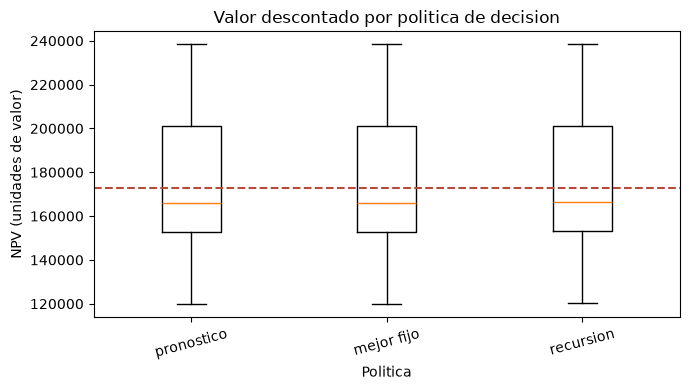

In [8]:
# Compare politicas fijas con el valor de recursividad por escenario.
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([fixed_scores.matrix[0], fixed_ex_ante, recourse_values],
    tick_labels=['pronostico', 'mejor fijo', 'recursion'])
ax.axhline(fixed_scores.expected.max(), color='#b64b3b', linestyle='--')
ax.set(title='Valor descontado por politica de decision',
    xlabel='Politica', ylabel='NPV (unidades de valor)')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()

### Figura 1

Cada caja resume valores descontados en las mismas 24 realizaciones sintéticas. Las cajas del pronóstico y del mejor plan fijo mantienen una asignación en todas; la recursión puede elegir entre una re-resolución y el menú finito tras observar cada realización. La línea discontinua marca la media del mejor plan fijo ex ante, no un óptimo de referencia. Medianas y dispersión describen solo este experimento con semilla fija. La superposición no es una prueba estadística y P10 no es un mínimo garantizado. El gráfico no valida la geología sintética ni la factibilidad más allá de las restricciones suministradas.

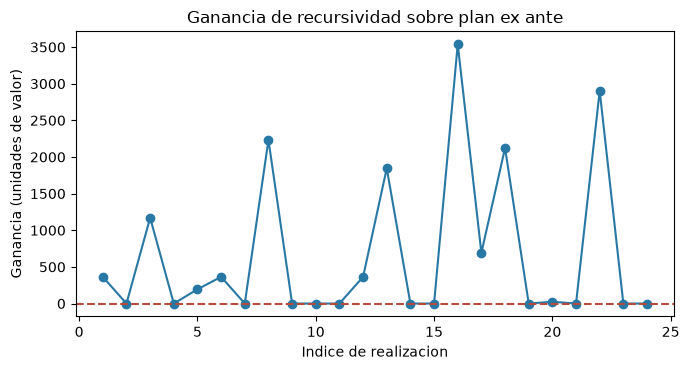

In [9]:
# Grafique la ganancia de recursividad y la referencia cero por realizacion.
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(1, len(paired_gain) + 1), paired_gain,
    marker='o', color='#2878a5')
ax.axhline(0, color='#b64b3b', linestyle='--')
ax.set(title='Ganancia de recursividad sobre plan ex ante',
    xlabel='Indice de realizacion', ylabel='Ganancia (unidades de valor)')
fig.tight_layout()
plt.show()

### Figura 2

Cada punto resta del valor de recursión la puntuación por realización del único plan escogido ex ante por su mayor media. La recursión puede quedar bajo ese plan en un escenario individual, visible bajo la línea cero, aunque su promedio no puede ser negativo porque quien decide puede elegir entre candidatos factibles tras observar una realización. La media es una cota inferior para este menú y heurística, no EVPI: la heurística puede omitir mejores planes y el menú no enumera todos los planes factibles.

## Resultados

**Respuesta:** La recursividad por escenario promedia **658.85 unidades de valor** sobre el mejor plan fijo ex ante (P10 0.00, P90 2199.70; ganancia positiva en 12 de 24 realizaciones). Esta cota combina la re-resolución por escenario con la selección del menú finito; no es EVPI. Los gráficos muestran la misma comparación pareada.

In [10]:
# Muestre las metricas calculadas citadas en la respuesta.
print(f'ganancia_media={paired_gain.mean():.2f}')
print(f'P10={np.quantile(paired_gain, 0.10):.2f}; P90={np.quantile(paired_gain, 0.90):.2f}')
print(f'escenarios_mejorados={(paired_gain > 1e-9).mean():.3f}')

ganancia_media=658.85
P10=0.00; P90=2199.70
escenarios_mejorados=0.500


## Resumen

El experimento sigue la práctica de análisis por escenarios deterministas de la literatura minera citada: resolver cada realización y comparar los planes resultantes sobre escenarios comunes. El método puede revelar si una adaptación económica responde a este generador mejor que un menú pequeño fijado de antemano. La conclusión queda limitada por el caso sintético de 48 bloques, 24 realizaciones equiprobables, tonelaje y capacidad fijos, y una re-resolución heurística sin certificado. Un estudio serio necesita simulaciones condicionales con procedencia, pesos calibrados, incertidumbre en las entradas relevantes, controles operacionales robustos y una optimización más potente. Para afirmar EVPI, aporte una resolución óptima probada por realización; para afirmar un resultado de programa estocástico, modele las decisiones estratégicas compartidas entre escenarios.

## Referencias

- Blom, Pearce y Cote, optimización estocástica en la práctica: https://arxiv.org/abs/2403.18213.
- Ramazan y Dimitrakopoulos, programación entera estocástica de dos etapas: https://doi.org/10.1007/s11081-012-9186-2.
- OreBlocks 0.6.3, `solve_cpit`, `perturb_values` y `evaluate_across`: https://pypi.org/project/oreblocks/0.6.3/.
- Esquema y constructor de instancias de PhaseFlow: `data-pipeline/pipeline/io/schema.py` y `data-pipeline/pipeline/model/instances.py` (MIT).